# 02 – EDA và trực quan hóa (BRFSS 2015)
*Phụ trách: TV2, TV4.* Hình lưu vào `DATA/figures/`. Chỉ dùng pandas, numpy, matplotlib, seaborn, scikit-learn. Đổi `RAW_FILE` / `TARGET` ở ô đầu để chạy trên file khác.

In [7]:

import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.linear_model import LinearRegression

# ---- Cấu hình (đường dẫn tính từ notebooks/02_EDA/) ----
RAW_DIR = "../../DATA/raw"
FIG_DIR = "../../DATA/figures"
RAW_FILE = "diabetes.csv"   # 3 lớp (Proposal). Đổi sang diabetes_binary_... nếu cần
TARGET = "Diabetes_binary"                                     # hoặc "Diabetes_binary"

os.makedirs(FIG_DIR, exist_ok=True)
sns.set_theme(style="whitegrid")
COLORS = {0: "#4C78A8", 1: "#F2A33A", 2: "#D1495B"}

df = pd.read_csv(os.path.join(RAW_DIR, RAW_FILE))
df.head()

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0


## Các hàm dùng chung trong notebook
Mỗi hàm làm đúng một việc và tự lưu hình vào `FIG_DIR`.

In [8]:
def check_structure(df, target):
    """In số dòng/cột, kiểu dữ liệu, giá trị thiếu, số giá trị khác nhau mỗi cột."""
    print(f"Số dòng, số cột: {df.shape} | số thuộc tính (không tính mục tiêu): {df.shape[1]-1}")
    print("Giá trị thiếu (tổng):", int(df.isna().sum().sum()))
    print("Kiểu dữ liệu:", df.dtypes.value_counts().to_dict())
    print("\nSố giá trị khác nhau mỗi cột:")
    print(df.nunique().to_string())


def count_duplicates(df, target):
    """Đếm dòng trùng (số lượng, tỷ lệ) và chia theo lớp mục tiêu."""
    dup = df.duplicated(keep="first")
    print(f"Dòng trùng lặp: {dup.sum():,} ({dup.mean():.2%})")
    t = pd.DataFrame({"tổng": df[target].value_counts().sort_index(),
                      "trùng": df[dup][target].value_counts().sort_index()}).fillna(0).astype(int)
    t["% lớp bị trùng"] = (t["trùng"] / t["tổng"] * 100).round(2)
    return t


def plot_target(df, target, fname="01_target_distribution.png"):
    """Biểu đồ cột phân bố biến mục tiêu, ghi số mẫu và %."""
    vc = df[target].value_counts().sort_index()
    pct = vc / vc.sum() * 100
    fig, ax = plt.subplots(figsize=(6.5, 4))
    bars = ax.bar([f"{int(k)}" for k in vc.index], vc.values,
                  color=[COLORS.get(int(k), "#888") for k in vc.index])
    for b, v, p in zip(bars, vc.values, pct.values):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({p:.1f}%)", ha="center", va="bottom")
    ax.set_ylim(0, vc.max() * 1.18); ax.set_xlabel(target); ax.set_ylabel("Số mẫu")
    ax.set_title(f"Phân bố biến mục tiêu {target}")
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, fname), dpi=150); plt.show()
    print(pct.round(2).to_dict(), "| tỷ lệ lớp lớn/nhỏ:", round(vc.max() / vc.min(), 1))


def plot_hist_box(df, cols=("BMI", "MentHlth", "PhysHlth"), fname="02_hist_boxplot_BMI_Ment_Phys.png"):
    """Histogram + boxplot cho các biến số, trả về bảng thống kê ngoại lệ (quy tắc IQR)."""
    fig, axes = plt.subplots(2, len(cols), figsize=(14, 7))
    rows = []
    for j, c in enumerate(cols):
        sns.histplot(df[c], bins=60 if c == "BMI" else 31, color="#4C78A8", ax=axes[0, j]); axes[0, j].set_title(f"Histogram {c}")
        sns.boxplot(x=df[c], color="#9ECAE9", fliersize=2, ax=axes[1, j]); axes[1, j].set_title(f"Boxplot {c}")
        x = df[c]; q1, q3 = x.quantile([.25, .75]); i = q3 - q1
        o = (x < q1 - 1.5 * i) | (x > q3 + 1.5 * i)
        rows.append([c, round(x.skew(), 2), x.median(), x.quantile(.99), x.max(), int(o.sum()),
                     round(o.mean() * 100, 1), round((x == 0).mean() * 100, 1), round((x == 30).mean() * 100, 1)])
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, fname), dpi=150); plt.show()
    return pd.DataFrame(rows, columns=["biến", "skew", "median", "p99", "max", "#ngoại lệ IQR", "% ngoại lệ", "% =0", "% =30"])


def plot_rate_by(df, target, fname="03_rate_by_Age_Income_HighBP_GenHlth.png"):
    """Tỷ lệ mắc bệnh (%) theo Age, Income, HighBP, GenHlth."""
    any_dm = (df[target] > 0).astype(int)
    top_dm = (df[target] == df[target].max()).astype(int)
    age_lab = {1:"18-24",2:"25-29",3:"30-34",4:"35-39",5:"40-44",6:"45-49",7:"50-54",8:"55-59",9:"60-64",10:"65-69",11:"70-74",12:"75-79",13:"80+"}
    specs = [("Age", age_lab), ("Income", None), ("HighBP", {0: "Không", 1: "Có"}),
             ("GenHlth", {1: "Rất tốt", 2: "Tốt", 3: "Khá", 4: "Kém", 5: "Rất kém"})]
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    out = {}
    for ax, (c, labs) in zip(axes.ravel(), specs):
        g_any = any_dm.groupby(df[c]).mean() * 100
        g_top = top_dm.groupby(df[c]).mean() * 100
        x = [labs[k] if labs else int(k) for k in g_any.index]
        ax.plot(x, g_any, marker="s", color=COLORS[1], label="Tiền ĐTĐ + ĐTĐ (>0)")
        if (any_dm != top_dm).any():
            ax.plot(x, g_top, marker="o", color=COLORS[2], label="Chỉ ĐTĐ (lớp cao nhất)")
        ax.set_title(f"Tỷ lệ mắc theo {c}"); ax.set_ylabel("% mắc"); ax.set_ylim(0); ax.legend(fontsize=8)
        if c == "Age": ax.tick_params(axis="x", rotation=45)
        out[c] = g_any.round(1).to_dict()
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, fname), dpi=150); plt.show()
    return out


def vif_table(X):
    """VIF của từng biến (tính bằng hồi quy tuyến tính của scikit-learn): VIF = 1 / (1 - R²)."""
    Z = (X - X.mean()) / X.std()
    v = {}
    for c in Z.columns:
        r2 = LinearRegression().fit(Z.drop(columns=c), Z[c]).score(Z.drop(columns=c), Z[c])
        v[c] = 1 / (1 - r2)
    return pd.Series(v).sort_values(ascending=False)


def plot_correlation(df, target, fname_matrix="04_correlation_matrix.png", fname_target="05_corr_with_target.png"):
    """Ma trận tương quan 21 thuộc tính + tương quan với 'có bệnh' + VIF."""
    X = df.drop(columns=target)
    corr = X.corr()
    fig, ax = plt.subplots(figsize=(12, 10))
    sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 6}, linewidths=.3, ax=ax)
    ax.set_title(f"Ma trận tương quan Pearson giữa {X.shape[1]} thuộc tính")
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, fname_matrix), dpi=150); plt.show()

    tc = X.corrwith((df[target] > 0).astype(int)).sort_values()
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.barh(tc.index, tc.values, color=np.where(tc.values > 0, COLORS[2], COLORS[0])); ax.axvline(0, color="k", lw=.8)
    ax.set_title(f"Tương quan với 'có bệnh' ({target} > 0)")
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, fname_target), dpi=150); plt.show()

    pairs = corr.abs().where(np.triu(np.ones(corr.shape, bool), 1)).stack().sort_values(ascending=False).head(6)
    return tc.sort_values(ascending=False), pairs, vif_table(X)

## 2.1 Kiểm tra cấu trúc dữ liệu

In [9]:
check_structure(df, TARGET)
for f in sorted(os.listdir(RAW_DIR)):
    if f.endswith('.csv'): print(f, pd.read_csv(os.path.join(RAW_DIR, f)).shape)

Số dòng, số cột: (253680, 22) | số thuộc tính (không tính mục tiêu): 21
Giá trị thiếu (tổng): 0
Kiểu dữ liệu: {dtype('int64'): 22}

Số giá trị khác nhau mỗi cột:
HighBP                   2
HighChol                 2
CholCheck                2
BMI                     84
Smoker                   2
Stroke                   2
HeartDiseaseorAttack     2
PhysActivity             2
Fruits                   2
Veggies                  2
HvyAlcoholConsump        2
AnyHealthcare            2
NoDocbcCost              2
GenHlth                  5
MentHlth                31
PhysHlth                31
DiffWalk                 2
Sex                      2
Age                     13
Education                6
Income                   8
Diabetes_binary          2
diabetes.csv (253680, 22)


**Nhận xét.** Bộ `diabetes_012` có **253.680 dòng × 22 cột** (21 thuộc tính + 1 biến mục tiêu), khớp với Proposal (~253.680 mẫu, 21 thuộc tính). Không có giá trị thiếu và cả 22 cột đều lưu dạng `float64` dù thực chất 14 cột là nhị phân 0/1 và 4 cột là biến thứ tự (Age 13 mức, Education 6, Income 8, GenHlth 5); chỉ BMI, MentHlth, PhysHlth là số đếm/liên tục. Việc "không thiếu" là do bộ dữ liệu đã được làm sạch từ BRFSS gốc, không có nghĩa khảo sát không có câu hỏi bị bỏ trống.

## 2.2 Dòng trùng lặp

In [10]:
count_duplicates(df, TARGET)

Dòng trùng lặp: 24,206 (9.54%)


,tổng,trùng,% lớp bị trùng
Diabetes_binary,,,
0,218334,23957,10.97
1,35346,249,0.70


**Nhận xét.** Có **23.899 dòng trùng (9,42%)**. Trùng lặp **phân bố rất lệch giữa các lớp**: 11,07% dòng lớp "không ĐTĐ" bị trùng, trong khi lớp tiền ĐTĐ gần như không có (0,04%, chỉ 2 dòng) và lớp ĐTĐ chỉ 0,70%. Nguyên nhân hợp lý là người khỏe mạnh có hồ sơ "điển hình" (ít bệnh, trẻ, BMI chuẩn) nên dễ giống hệt nhau trên 21 biến chủ yếu là nhị phân/thứ tự, tức nhiều dòng trùng là *người khác nhau có cùng đặc trưng* chứ không hẳn lỗi nhập liệu. Điều này ảnh hưởng quyết định ở notebook 03.

## 2.3 Phân bố biến mục tiêu

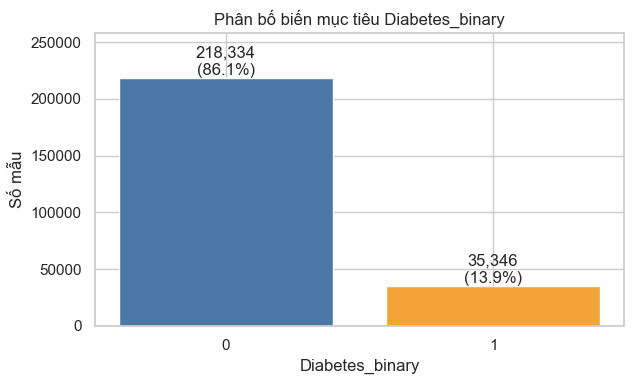

{0: 86.07, 1: 13.93} | tỷ lệ lớp lớn/nhỏ: 6.2


In [11]:
plot_target(df, TARGET)

**Nhận xét.** Phân bố là **84,2% / 1,8% / 13,9%** (không ĐTĐ / tiền ĐTĐ / ĐTĐ), nên con số "~84% / 2% / 14%" trong Proposal là đúng. Lớp tiền ĐTĐ chỉ có 4.631 mẫu, nhỏ hơn lớp lớn nhất khoảng **46 lần**, nên accuracy dễ đánh lừa (đoán toàn "không ĐTĐ" đã đạt ~84%). Cần stratified split và các độ đo như macro-F1, recall từng lớp, PR-AUC, cộng thêm class weight hoặc resampling (chỉ áp dụng trên train).

## 2.4 Histogram và boxplot: BMI, MentHlth, PhysHlth

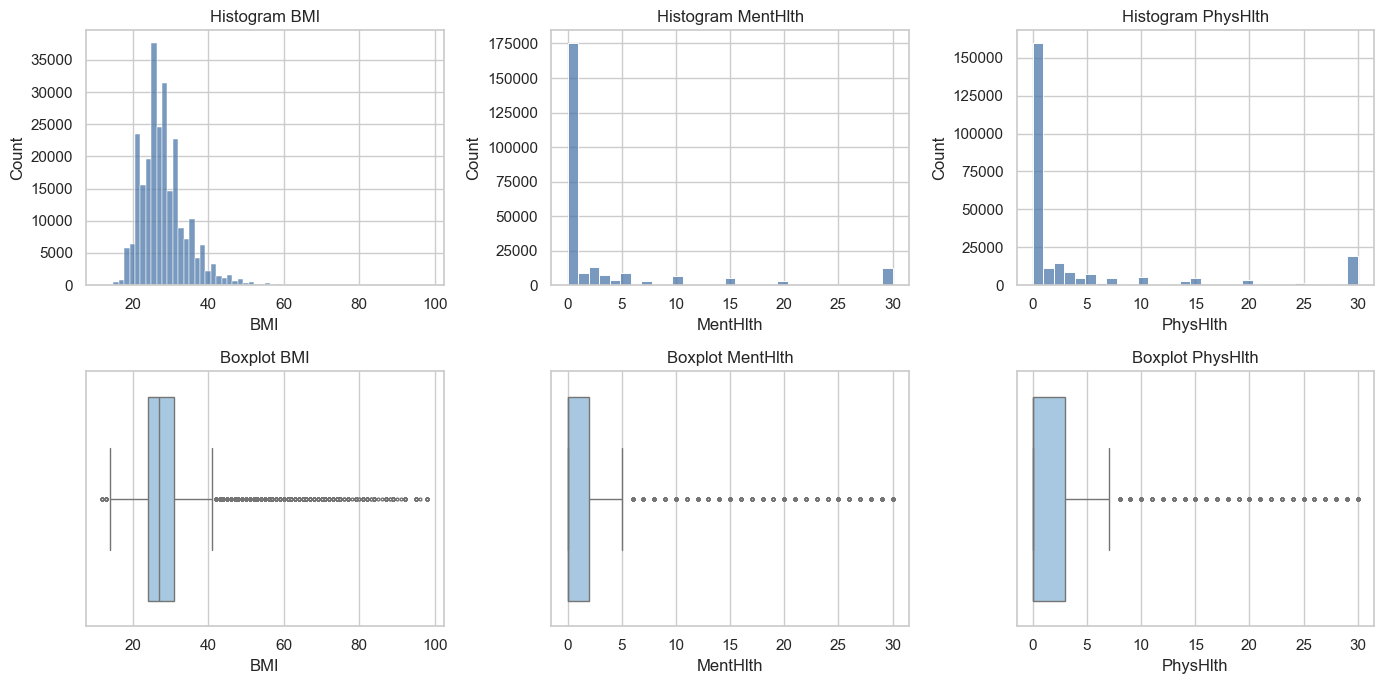

    biến  skew  median  p99  max  #ngoại lệ IQR  % ngoại lệ  % =0  % =30
     BMI  2.12    27.0 50.0   98           9847         3.9   0.0    5.7
MentHlth  2.72     0.0 30.0   30          36208        14.3  69.3    4.8
PhysHlth  2.21     0.0 30.0   30          40949        16.1  63.1    7.6

BMI>=50: 2547 | BMI>=60: 868 | BMI<15: 68 | BMI max: 98


In [12]:
outlier_table = plot_hist_box(df)
print(outlier_table.to_string(index=False))
print('\nBMI>=50:', (df.BMI>=50).sum(), '| BMI>=60:', (df.BMI>=60).sum(), '| BMI<15:', (df.BMI<15).sum(), '| BMI max:', df.BMI.max())

**Nhận xét.**
- **BMI** lệch phải (skew ≈ 2,1), trung vị 27, p99 = 50 nhưng max = 98. Quy tắc IQR gắn cờ ~9.850 điểm (3,9%) là ngoại lệ, phần lớn là người béo phì nặng có thật; chỉ một số rất ít giá trị cực đoan (BMI ≥ 60: 868 mẫu, tối đa 98) đáng nghi là nhập sai hoặc tự khai sai.
- **MentHlth** và **PhysHlth** là số ngày xấu trong 30 ngày nên bị chặn trong [0, 30]: ~69% và ~63% mẫu bằng 0, trong khi ~4,8% và ~7,6% bằng đúng 30, tạo phân bố hai đỉnh ở hai đầu. Boxplot gắn cờ ~14–16% dòng là "ngoại lệ" nhưng đó là người có sức khỏe kém thật, không phải lỗi, nên không nên xóa.
- Vì vậy chỉ BMI cần cân nhắc xử lý ngoại lệ; hai biến còn lại giữ nguyên.

## 2.5 Tỷ lệ mắc bệnh theo Age, Income, HighBP, GenHlth

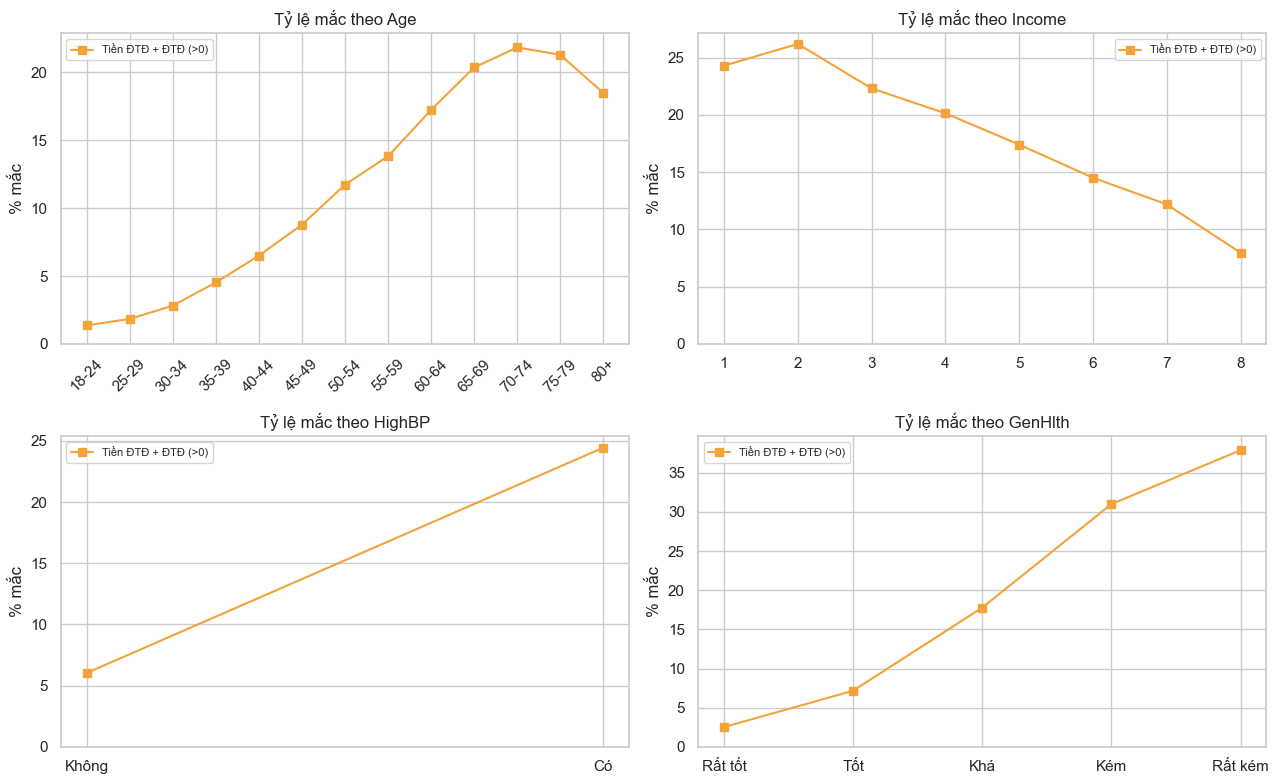

Age {1: 1.4, 2: 1.8, 3: 2.8, 4: 4.5, 5: 6.5, 6: 8.8, 7: 11.7, 8: 13.8, 9: 17.2, 10: 20.4, 11: 21.8, 12: 21.3, 13: 18.5}
Income {1: 24.3, 2: 26.2, 3: 22.3, 4: 20.1, 5: 17.4, 6: 14.5, 7: 12.2, 8: 8.0}
HighBP {0: 6.0, 1: 24.4}
GenHlth {1: 2.5, 2: 7.2, 3: 17.8, 4: 31.0, 5: 37.9}


In [13]:
rates = plot_rate_by(df, TARGET)
for k, v in rates.items(): print(k, v)

**Nhận xét.** Tỷ lệ mắc (tiền ĐTĐ + ĐTĐ) tăng gần như đơn điệu theo **tuổi**, từ 1,7% (18–24) lên đỉnh ~24% ở nhóm 70–74 rồi giảm nhẹ (21% ở 80+), có thể do hiệu ứng người sống sót. **Thu nhập** có chiều ngược: nhóm thấp nhất (mức 1–2) ~27–29% so với 9,1% ở nhóm cao nhất (mức 8). **Huyết áp cao** làm tỷ lệ gấp ~3,8 lần (27,1% so với 7,2%), còn **GenHlth** phân tầng mạnh nhất: 3,2% ở "rất tốt" so với 40,8% ở "rất kém". Đây là quan hệ mô tả, chưa phải nhân quả (ví dụ người đã bị ĐTĐ có thể tự đánh giá sức khỏe thấp hơn).

## 2.6 Ma trận tương quan, tương quan với mục tiêu và đa cộng tuyến

In [14]:
  import sys; print(sys.executable)

C:\Users\ADMIN\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe


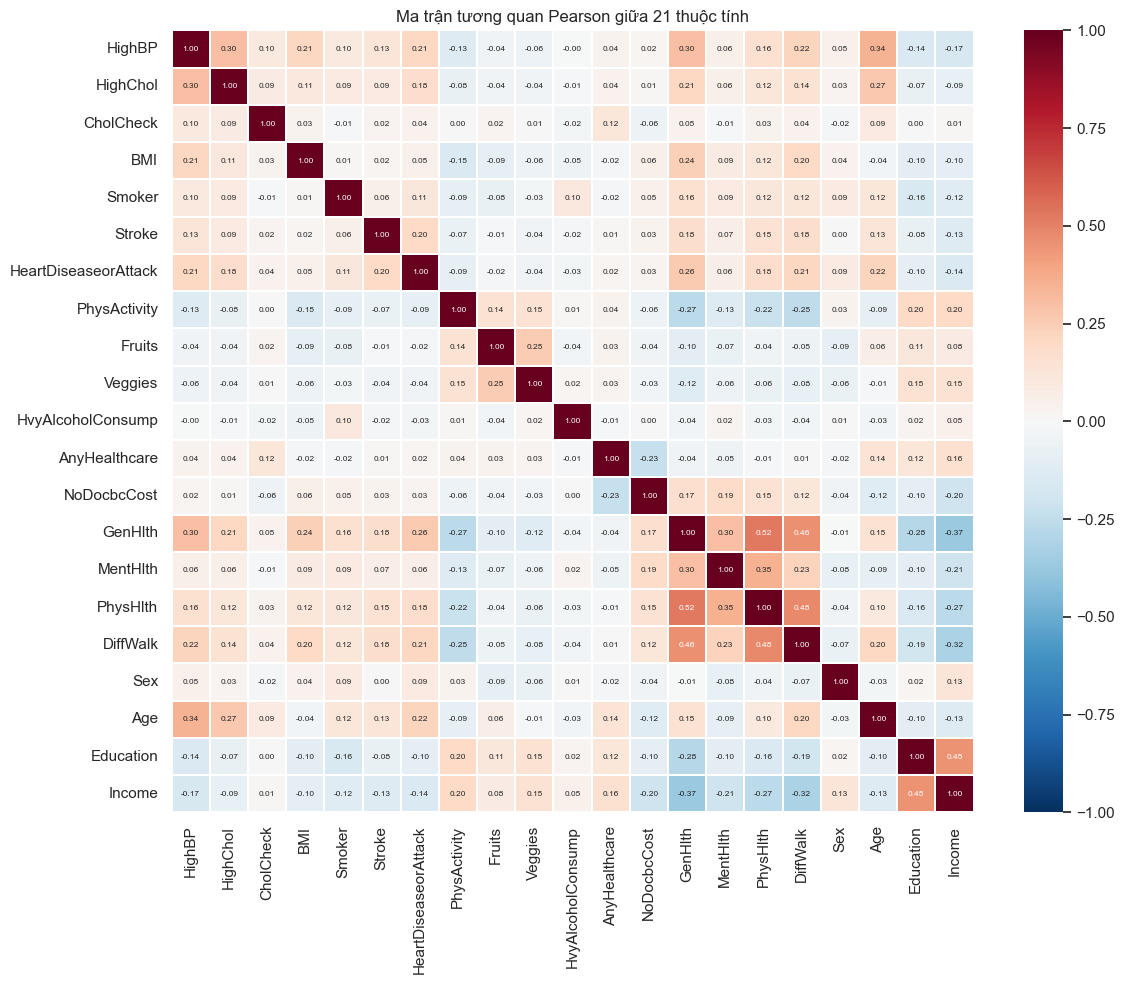

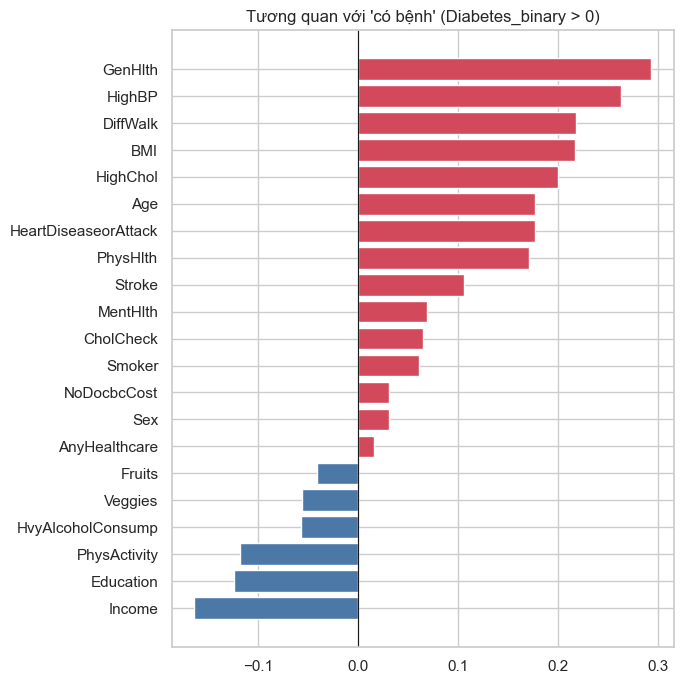

GenHlth                 0.294
HighBP                  0.263
DiffWalk                0.218
BMI                     0.217
HighChol                0.200
Age                     0.177
HeartDiseaseorAttack    0.177
PhysHlth                0.171
Stroke                  0.106
MentHlth                0.069
CholCheck               0.065
Smoker                  0.061
NoDocbcCost             0.031
Sex                     0.031
AnyHealthcare           0.016
Fruits                 -0.041
Veggies                -0.057
HvyAlcoholConsump      -0.057
PhysActivity           -0.118
Education              -0.124
Income                 -0.164

Cặp tương quan cao nhất:
GenHlth    PhysHlth    0.524
PhysHlth   DiffWalk    0.478
GenHlth    DiffWalk    0.457
Education  Income      0.449
GenHlth    Income      0.370
MentHlth   PhysHlth    0.354

VIF cao nhất:
GenHlth     1.80
PhysHlth    1.62
DiffWalk    1.53
Income      1.50
Age         1.35
HighBP      1.33


In [15]:
corr_target, top_pairs, vif = plot_correlation(df, TARGET)
print(corr_target.round(3).to_string())
print('\nCặp tương quan cao nhất:'); print(top_pairs.round(3).to_string())
print('\nVIF cao nhất:'); print(vif.head(6).round(2).to_string())

**Nhận xét.** Biến tương quan dương mạnh nhất với mục tiêu là **GenHlth (0,30)**, rồi HighBP (0,27), BMI (0,22), DiffWalk (0,22), HighChol (0,21) và Age (0,19); chiều âm là Income (−0,17), Education (−0,13) và PhysActivity (−0,12). Tất cả chỉ yếu đến vừa (|r| < 0,31), nên không biến đơn nào đủ để dự báo. Giữa các thuộc tính, cặp cao nhất là GenHlth–PhysHlth (0,52), DiffWalk–PhysHlth (0,48), GenHlth–DiffWalk (0,46) và Income–Education (0,45): có nhóm "sức khỏe thể chất" và nhóm "kinh tế–học vấn" liên quan nhau, nhưng VIF lớn nhất chỉ ≈ 1,8 (GenHlth), thấp hơn nhiều ngưỡng thường dùng 5–10, nên chưa có đa cộng tuyến nghiêm trọng và có thể giữ toàn bộ 21 biến; với mô hình tuyến tính vẫn nên dùng regularization. Pearson trên biến nhị phân/thứ tự chỉ là thước đo gần đúng.